# **Business Background**

The Marketing team has observed that customers frequently purchase multiple products within the same transaction. However, the current product recommendation system does not effectively leverage these purchasing patterns, resulting in missed opportunities for cross-selling and revenue growth.

Management would like to better understand customer buying behavior by analyzing historical transaction data to identify product groups that are commonly purchased together. The insights generated will be used to improve product recommendations, promotional campaigns, and online storefront merchandising.

---

# **Project Objectives**

Conduct a Market Basket Analysis (Association Rule Mining) on historical transaction data to:

* Identify product combinations with the strongest purchase associations.
* Understand the customer behavior and motivations behind these purchasing patterns.
* Recommend actionable strategies to improve cross-selling, average order value (AOV), and customer experience.



## **1. Import packages & dataset**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

import warnings
warnings.filterwarnings('ignore')

In [3]:
# import dataset

sales = pd.read_csv('/content/drive/MyDrive/BT-XomDA/B7-BTVN/EcomSales.csv')
product = pd.read_csv('/content/drive/MyDrive/BT-XomDA/B7-BTVN/Product.csv')

#### __init.

In [4]:
import re

def check_dataframe_boxplot(df, show_head=True, plot_boxplots=True):
    """
    Perform a comprehensive DataFrame inspection:
    1. Metadata (df.info())
    2. Duplicate check (df.duplicated().sum())
    3. Missing values check (df.isna().sum())
    4. Descriptive statistics (df.describe().T) +
       outlier statistics based on IQR +
       missing value statistics
    5. Preview data (df.head())

    Parameters:
    ----------
    df : pandas.DataFrame
        DataFrame to inspect.
    show_head : bool, default=True
        Display the first 5 rows.
    plot_boxplots : bool, default=True
        Draw box plots for each numeric column in the DataFrame.
    """

    print("=" * 65)
    print("1. DATASET METADATA")
    print("=" * 65)
    df.info()
    print("\n")

    print("=" * 65)
    print("2. DUPLICATE DATA CHECK")
    print("=" * 65)
    dup_count = df.duplicated().sum()
    dup_ratio = (dup_count / len(df)) * 100 if len(df) > 0 else 0
    print(f"- Number of duplicate rows: {dup_count:,} ({dup_ratio:.2f}%)")
    print("\n")

    print("=" * 65)
    print("3. MISSING VALUES CHECK")
    print("=" * 65)
    null_count = df.isna().sum()
    null_ratio = (df.isna().sum() / len(df)) * 100 if len(df) > 0 else 0

    missing_df = pd.DataFrame(
        {
            "Data Type": df.dtypes,
            "Missing Count": null_count,
            "Missing Ratio (%)": null_ratio.round(2),
        }
    )

    missing_only = missing_df[missing_df["Missing Count"] > 0]

    if not missing_only.empty:
        print(missing_only.to_string())
    else:
        print("-> No missing values found in any column.")
    print("\n")

    print("=" * 65)
    print("4. DESCRIPTIVE STATISTICS & OUTLIER DETECTION")
    print("=" * 65)

    num_cols = df.select_dtypes(include=[np.number]).columns.to_list()
    num_cols = [
        col for col in num_cols
        if not re.search(r"(^id$|.*id$)", col.lower())
    ]

    n_cols = len(num_cols)

    if n_cols > 0:
        # Basic descriptive statistics
        desc = df[num_cols].describe().T

        # Calculate outlier counts using the IQR rule
        # (Q1 - 1.5*IQR to Q3 + 1.5*IQR)
        outlier_counts = {}

        for col in num_cols:
            q1 = df[col].quantile(0.25)
            q3 = df[col].quantile(0.75)
            iqr = q3 - q1

            lower = q1 - 1.5 * iqr
            upper = q3 + 1.5 * iqr

            outlier_counts[col] = (
                ((df[col] < lower) | (df[col] > upper)).sum()
            )

        desc["outliers_iqr"] = pd.Series(outlier_counts)
        desc["outliers_iqr_ratio"] = (
            desc["outliers_iqr"] / len(df)
        ) * 100

        desc["missing"] = df[num_cols].isna().sum()
        desc["missing_ratio"] = (
            df[num_cols].isna().mean() * 100
        ).round(2)

        print(desc.round(2).to_string())
        print("\n")

    else:
        print("-> No numeric columns found in the DataFrame.")

    print("\n")

    # Preview first 5 rows
    if show_head:
        print("=" * 65)
        print("5. PREVIEW OF THE FIRST 5 ROWS")
        print("=" * 65)
        print(df.head().to_string())
        print("\n")

## **2. EDA & Handle outliers**

In [5]:
# check dataframes
df_table = {
    'SALES': sales,
    'PRODUCT': product
}

for table_name, df in df_table.items():
    print(f'CHECK DATASET IN TABLE {table_name}')
    check_dataframe_boxplot(df, show_head=True)

CHECK DATASET IN TABLE SALES
1. DATASET METADATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   RowID        51290 non-null  int64  
 1   OrderID      51290 non-null  object 
 2   OrderDate    51290 non-null  object 
 3   CustomerID   51290 non-null  object 
 4   Segment      51290 non-null  object 
 5   RegionCode   51290 non-null  object 
 6   ProductCode  51290 non-null  object 
 7   Quantity     51290 non-null  int64  
 8   Sales        51290 non-null  int64  
 9   Discount     51290 non-null  float64
 10  Profit       51290 non-null  float64
dtypes: float64(2), int64(3), object(6)
memory usage: 4.3+ MB


2. DUPLICATE DATA CHECK
- Number of duplicate rows: 0 (0.00%)


3. MISSING VALUES CHECK
-> No missing values found in any column.


4. DESCRIPTIVE STATISTICS & OUTLIER DETECTION
            count    mean     std     min   25%   50% 

In [6]:
# transform Order Date to datetime
sales['OrderDate'] = pd.to_datetime(sales['OrderDate'])

In [7]:
sales['OrderDate'].describe()

,OrderDate
count,51290
mean,2022-05-11 21:26:49.155781120
min,2020-01-01 00:00:00
25%,2021-06-19 00:00:00
50%,2022-07-08 00:00:00
75%,2023-05-22 00:00:00
max,2023-12-31 00:00:00


In [8]:
sales['OrderYear'] = sales['OrderDate'].dt.year
sales['OrderMonth'] = sales['OrderDate'].dt.month
sales['YearMonth'] = sales['OrderDate'].dt.to_period('M')

sales.head(2)

,RowID,OrderID,OrderDate,CustomerID,Segment,RegionCode,ProductCode,Quantity,Sales,Discount,Profit,OrderYear,OrderMonth,YearMonth
0,25221,IN-2012-TH211151-41003,2020-04-04,TH-211151,Corporate,RRR0001,P000001,13,416,0.0,208.0,2020,4,2020-04
1,29464,ID-2013-BD116051-41518,2021-09-01,BD-116051,Consumer,R0002,PPP000002,4,20,0.0,10.0,2021,9,2021-09


In [9]:
# topline summary
summary = (sales.groupby(by='OrderYear', observed=True).agg(order_qty=('OrderID', 'nunique'),
                                                            customer=('CustomerID', 'nunique'),
                                                            revenue=('Sales', 'sum'),
                                                            profit=('Profit', 'sum')
                                                            )
)

total_row = pd.DataFrame({
    'order_qty': [sales['OrderID'].nunique()],
    'customer': [sales['CustomerID'].nunique()],
    'revenue': [sales['Sales'].sum()],
    'profit': [sales['Profit'].sum()]
    }, index=['Total'])

summary = pd.concat([summary, total_row])
summary

,order_qty,customer,revenue,profit
2020,4515,4164,1148361,207116.122
2021,5473,4949,1405876,259696.964
2022,6883,6113,1770790,318671.888
2023,8857,7624,2192647,279928.676
Total,25728,17415,6517674,1065413.650


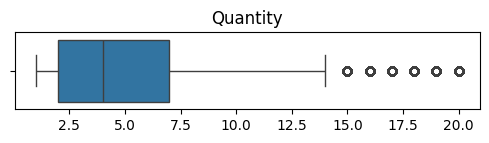

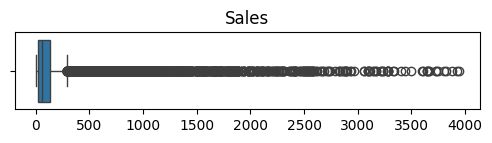

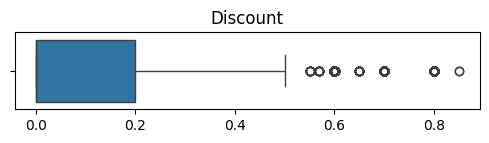

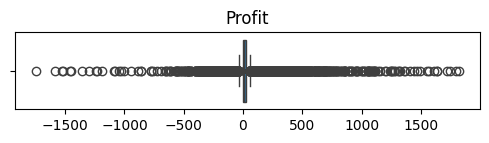

In [10]:
for col in ['Quantity', 'Sales', 'Discount', 'Profit']:
  plt.figure(figsize = (6,1))
  sns.boxplot(data = sales, x = col)
  plt.xlabel('')
  plt.title(col)
  plt.show()

In [11]:
# examine frequency of products in unique orders
frequency = sales.groupby('ProductCode')['OrderID'].nunique().sort_values(ascending=False)
frequency.mean()

np.float64(14.306316377864729)

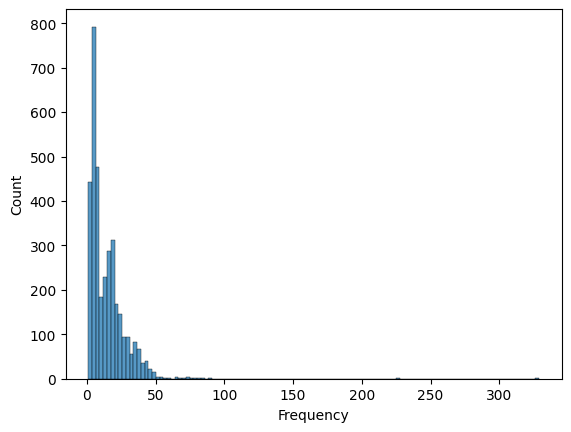

In [12]:
sns.histplot(frequency)
plt.xlabel('Frequency');

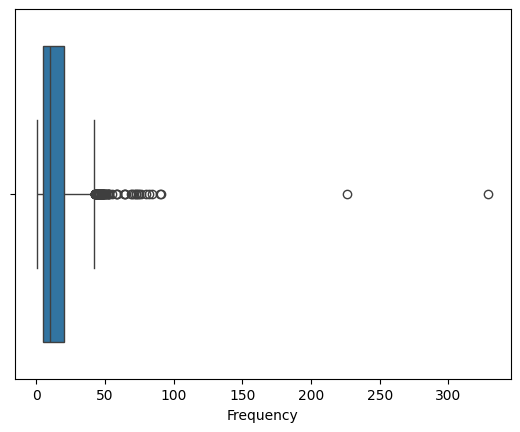

In [13]:
sns.boxplot(x=frequency)
plt.xlabel('Frequency');



* The dataset contains all transactions recorded over a four-year period, from 2020 to 2023, comprising 25,728 orders placed by 17,415 unique customers.

* Quantity, Sales, Discount, and Profit exhibit right-skewed distributions with numerous outliers, a common characteristic of business transaction data. Since these outliers may contain valuable business insights rather than data errors, they will be preserved and included in the analysis rather than being removed or capped.

* In terms of product order frequency, half of products are placed in fewer than 14 unique orders, and the majority of products appear in fewer than 50 ones. However, several outliers are observed, with some products appearing in more than 50 orders and up to over 300 orders.

* The dataset does not contain any significant anomalies or missing values that require further treatment. Additionally, the `OrderDate` column has been successfully converted to the appropriate datetime data type for subsequent analysis.


In [14]:
# number of SKUs by category and sub-category
product.groupby(by=['Category', 'Subcategory'], observed=True)['ProductCode'].nunique()

Category              Subcategory                 
Body care             Body soaps and washes           1133
                      Nail care products              2386
                      bath oils, bubbles and soaks    1474
                      body moisturizers               1551
                      face masks and exfoliators      1498
                      hand creams                     1577
                      vitamins and supplements        1929
Face care             face moisturizing products      1885
Hair care             hair colors and toners          1811
                      shampoos and conditioners       2259
Home and Accessories  Accessories                     1797
                      brushes and applicators         1913
                      candles, sprays, diffusers      1464
                      fragrances                       738
Make up               Eye shadows and pencils         2178
                      Lipsticks                       1234
                      foundations and concealers      1529
Name: ProductCode, dtype: int64

## **3. MBA analysis in SKU-level**

In [15]:
# substitute product code by its name

df = pd.merge(sales[['OrderID','ProductCode']],
              product[['ProductCode', 'Product', 'Subcategory']],
              on='ProductCode', how='inner')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51288 entries, 0 to 51287
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   OrderID      51288 non-null  object
 1   ProductCode  51288 non-null  object
 2   Product      51288 non-null  object
 3   Subcategory  51288 non-null  object
dtypes: object(4)
memory usage: 1.6+ MB


In [16]:
# parse different unique products in the same orderID
basket = df.groupby(by=['OrderID'])['Product'].apply(set).reset_index()
basket = basket['Product'].to_list()

basket[:3]

[{'Gold Whisper Brooch', 'Tata Harper Smoothing Body Scrub'},
 {"L'Oréal Paris EverPure Sulfate-Free Moisture Conditioner",
  'Schwarzkopf Live Intense Color - Mystic Violet'},
 {"Clairol Nice'n Easy Permanent Hair Color - Light Warm Brown",
  'Sephora Collection PRO Small Stippling Brush #42'}]

In [17]:
# transform into One-hot format

te = TransactionEncoder()
te_ary = te.fit(basket).transform(basket)
df_basket = pd.DataFrame(te_ary, columns=te.columns_)
df_basket.head()

,Acqua di Parma Blu Mediterraneo Arancia di Capri Bath & Shower Gel,Aesop Geranium Leaf Hydrating Body Treatment,Aesop Petitgrain Reviving Body Gel,Aesop Rind Concentrate Body Balm,Ahava Dead Sea Mineral Bath Salts,Ahava Dead Sea Osmoter™ Concentrate Even Tone Serum,Ahava Mineral Bath Salts,Ahava Mineral Shower Gel,Amethyst Blaze Bracelet,Amethyst Bliss Bracelet,...,Zoya Nail Polish Remy Deep Teal with Glitter,Zoya Nail Polish Robyn Bright Blue,Zoya Nail Polish Rue Soft Blush,Zoya Nail Polish Sooki Bright Red,Zoya Nail Polish Spencer Camel Beige,Zoya Nail Polish Storm Black with Holographic Glitter,Zoya Nail Polish Talia Bright Turquoise,Zoya Nail Polish Trixie Metallic Silver,Zoya Nail Polish Willa Glossy Black,Zoya Nail Polish Yara Olive Green with Gold Shimmer
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


> According to the frequency of products in unique orders, I select a min_support thresold of 0.1% total orders, which is equivalent to approximately 25 orders.

In [18]:
frequent_itemsets = apriori(df_basket,
                            min_support=0.001,
                            use_colnames=True,
                            max_len=None)
frequent_itemsets.sort_values(by='support', ascending=False)
frequent_itemsets.head()

,support,itemsets
0,0.001555,(Anastasia Beverly Hills Brow Definer Auburn)
1,0.001516,(Anastasia Beverly Hills Brow Definer Dark Brown)
2,0.001166,(Anastasia Beverly Hills Brow Definer Granite)
3,0.001671,(Anastasia Beverly Hills Brow Definer Soft Brown)
4,0.001166,(Anastasia Beverly Hills Brow Wiz Ebony)


In [19]:
print(f'Number of itemsets with frequency >= 0.01 is {len(frequent_itemsets)}')

Number of itemsets with frequency >= 0.01 is 538


In [20]:
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(len)
frequent_itemsets['length'].value_counts()

,count
length,
1,538


#### **Findings**

* At the SKU level, 578 frequent itemsets were identified with min_support = 0.001; however, all of them consisted of single-item itemsets. As a result, no association rules could be generated for further evaluation using confidence and lift.


* The cosmetics industry typically has a large and highly fragmented SKU portfolio. In this dataset alone, there are approximately 20,000 SKUs, differentiated by brand, shade, size, fragrance, and other attributes. For example, 4 of the top 5 most frequent items are the same product line from Anastasia Beverly Hills, differing only in shade.
| Top 5 frequent items|
|---|
| Anastasia Beverly Hills Brow Definer Aubur |
| Anastasia Beverly Hills Brow Definer Dark Brown |
| Anastasia Beverly Hills Brow Definer Granite |
| Anastasia Beverly Hills Brow Definer Soft Brown|
| Anastasia Beverly Hills Brow Wiz Ebony |


> **Therefore, SKU-level Market Basket Analysis is not the most suitable approach for this dataset. A more effective approach is to conduct MBA at the subcategory level, where product groupings better represent customer needs (e.g., moisturizers, exfoliators, hair care) and are more likely to reveal meaningful purchasing associations.**


## **4. MBA analysis in Subcategory level**

In [21]:
subcat_basket = df.groupby(by='OrderID')['Subcategory'].apply(set).reset_index()
subcat_basket = subcat_basket['Subcategory'].to_list()

In [22]:
subcat_basket[:3]

[{'face masks and exfoliators', 'hand creams'},
 {'Nail care products', 'candles, sprays, diffusers'},
 {'hand creams', 'shampoos and conditioners'}]

In [23]:
# transform into one-hot array
subcat_te = TransactionEncoder()
subcat_te_array = subcat_te.fit(subcat_basket).transform(subcat_basket)

df_subcat_basket = pd.DataFrame(subcat_te_array, columns = subcat_te.columns_)
df_subcat_basket.head()

,Accessories,Body soaps and washes,Eye shadows and pencils,Lipsticks,Nail care products,"bath oils, bubbles and soaks",body moisturizers,brushes and applicators,"candles, sprays, diffusers",face masks and exfoliators,face moisturizing products,foundations and concealers,fragrances,hair colors and toners,hand creams,shampoos and conditioners,vitamins and supplements
0,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,False
1,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False
3,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,True,True
4,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False


In [24]:
frequent_subcat = apriori(df_subcat_basket,
                          min_support= 0.001,
                          use_colnames=True,
                          max_len=3)

print(f'{len(frequent_subcat)} itemsets are identified having support >= 0.1%')
print('\nTop 5 itemsets with highest support scores:')
print(frequent_subcat.nlargest(5, columns='support'))

582 itemsets are identified having support >= 0.1%

Top 5 itemsets with highest support scores:
     support                        itemsets
4   0.199122            (Nail care products)
15  0.160836     (shampoos and conditioners)
5   0.147582  (bath oils, bubbles and soaks)
14  0.146883                   (hand creams)
6   0.143812             (body moisturizers)


In [25]:
frequent_subcat['length'] = frequent_subcat['itemsets'].apply(len)
frequent_subcat['length'].value_counts()

,count
length,
3,429
2,136
1,17


In [26]:
# convert to a dataframe of association rules
# filter those with lift score >= 1.2, meaning that only those pairs with at least 20% probability higher than probability of antecedents and consequents if they are independent are justify further

rules = association_rules(frequent_subcat,
                          metric='lift',
                          min_threshold=1.2)
rules.head(2)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,"(candles, sprays, diffusers)",(fragrances),0.079796,0.023282,0.00241,0.030200,1.297125,1.0,0.000552,1.007133,0.248928,0.023938,0.007083,0.066853
1,(fragrances),"(candles, sprays, diffusers)",0.023282,0.079796,0.00241,0.103506,1.297125,1.0,0.000552,1.026447,0.234525,0.023938,0.025766,0.066853


In [27]:
rules.describe()

,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
count,2004.000000,2004.000000,2004.000000,2004.000000,2004.000000,2004.0,2004.000000,2004.000000,2004.000000,2004.000000,2004.000000,2004.000000
mean,0.068059,0.068059,0.002244,0.094065,1.389208,1.0,0.000607,1.031584,0.294071,0.016918,0.029630,0.094065
std,0.059996,0.059996,0.000954,0.083266,0.142486,0.0,0.000286,0.033657,0.075768,0.005740,0.030302,0.024349
min,0.002954,0.002954,0.001011,0.005075,1.200371,1.0,0.000182,1.001449,0.168243,0.005012,0.001447,0.038128
25%,0.012671,0.012671,0.001477,0.018088,1.278449,1.0,0.000382,1.004819,0.233301,0.012587,0.004796,0.076329
50%,0.027830,0.027830,0.002021,0.046258,1.358669,1.0,0.000550,1.016185,0.284840,0.016525,0.015927,0.092311
75%,0.123406,0.123406,0.002760,0.164520,1.470934,1.0,0.000768,1.052027,0.345751,0.020604,0.049454,0.109225
max,0.199122,0.199122,0.005480,0.356322,1.983334,1.0,0.001841,1.244222,0.550864,0.035602,0.196285,0.181186


In [28]:
top_rules = rules[['antecedents','consequents','support','confidence','lift']]
top_rules = top_rules[top_rules['confidence'] >= 0.1]
top_rules = top_rules.sort_values(by='lift', ascending=False).reset_index(drop=True)
top_rules.head(2)

,antecedents,consequents,support,confidence,lift
0,"(candles, sprays, diffusers, Accessories)",(hair colors and toners),0.001205,0.182353,1.932280
1,"(candles, sprays, diffusers, shampoos and cond...",(hair colors and toners),0.002138,0.180921,1.917107


## **5. Visualizations to interpret insights in top association rules**

In [29]:
# create combination column name of antecedents and consequents
top_rules['antecedents_str'] = top_rules['antecedents'].apply(lambda x: '/ '.join(list(x))).astype('str')
top_rules['consequents_str'] = top_rules['consequents'].apply(lambda x: '/ '.join(list(x))).astype('str')

top_rules['combo_str'] = top_rules['antecedents_str'] + ' + ' + top_rules['consequents_str']

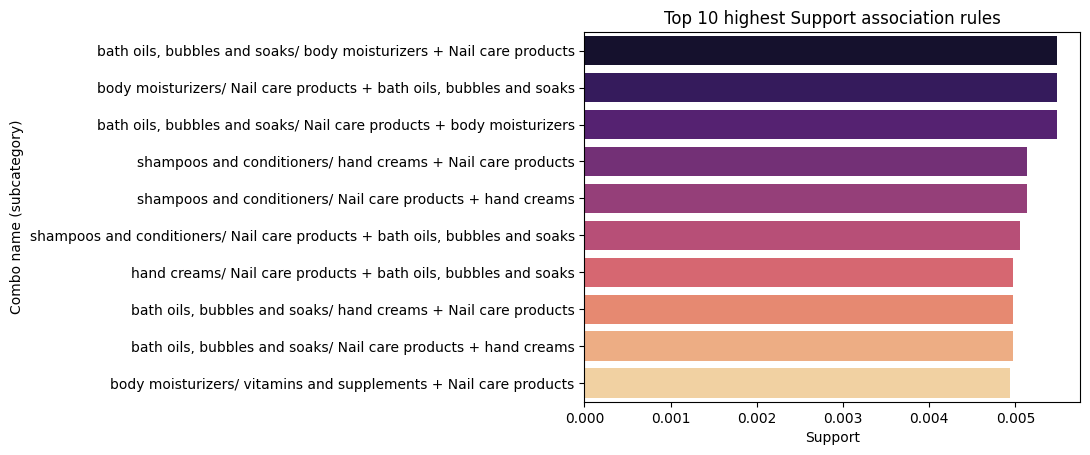

In [30]:
# visualize top 10 highest support association rules
sns.barplot(data=top_rules.nlargest(10,'support'),
            y='combo_str',
            x ='support',
            hue='combo_str',
            palette='magma')
plt.xlabel('Support')
plt.ylabel('Combo name (subcategory)')
plt.title('Top 10 highest Support association rules')
plt.show()

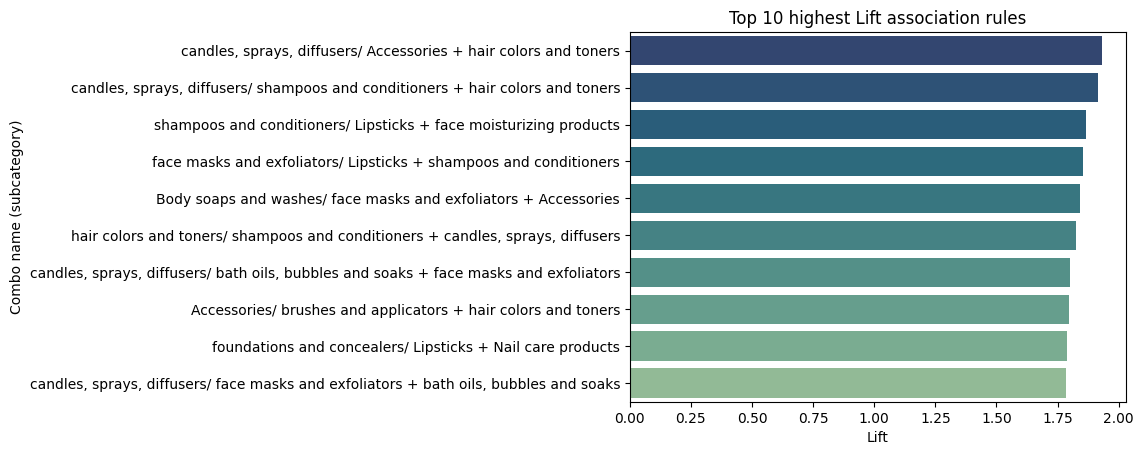

In [31]:
# visualize top 10 highest lift association rules

sns.barplot(data=top_rules.nlargest(10,'lift'),
            y='combo_str',
            x ='lift',
            hue='combo_str',
            palette='crest_r')
plt.xlabel('Lift')
plt.ylabel('Combo name (subcategory)')
plt.title('Top 10 highest Lift association rules')
plt.show()

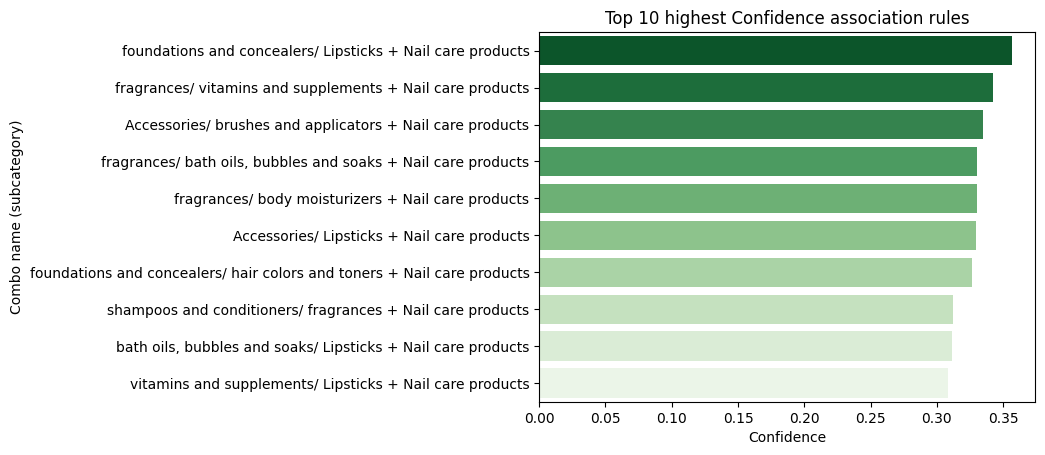

In [32]:
# visualize top 10 highest confidence association rules
sns.barplot(data=top_rules.nlargest(10,'confidence'),
            y='combo_str',
            x ='confidence',
            hue='combo_str',
            palette='Greens_r')
plt.xlabel('Confidence')
plt.ylabel('Combo name (subcategory)')
plt.title('Top 10 highest Confidence association rules')
plt.show()

#### **Key Insights from the 3 charts above**

* **Nail Care Products** is the most prevalent subcategory, with a support of approximately 20% of all orders. As a result, its frequent appearance among the top combinations by support and confidence is driven not only by purchasing associations but also by its inherently high popularity.


* **Top 10 combinations by support** are primarily concentrated in personal care categories, including bath oils, body moisturizers, hand creams, and shampoos & conditioners. These combinations represent the most commonly purchased product groupings across the customer base.


* **Top 10 combinations by confidence** indicate that when customers purchase certain cosmetics, accessories, or body care products, the probability of also purchasing Nail Care Products ranges from approximately 31% to 36%. However, this result should be interpreted with caution, as Nail Care Products already has a high baseline support of 20%. Therefore, the elevated confidence may partially reflect the category's overall popularity rather than a particularly strong cross-selling relationship.


* **Top 10 combinations by lift** reveal a different pattern. The strongest associations are consistently observed among product categories related to hair care, facial skincare, body cleansing, and at-home wellness products (including home fragrance, candles, diffusers, and spa products). These categories repeatedly appear together in different combinations, suggesting stronger behavioral relationships than those identified solely by support or confidence.<br>
> For example, hair care products (such as Shampoos & Conditioners and Hair Colors & Toners) appear in 6 of the top 10 lift-based combinations, including 3 combinations linked to home fragrance categories (Candles, Sprays & Diffusers).


* Notably, there is **little overlap among the top 10 combinations selected by support, confidence, and lift**. This confirms that the strongest associations (high lift) are not necessarily the most common combinations (high support) or the combinations with the highest conditional purchase probabilities (high confidence).




### **Visualize all 3 metrics into a bubble chart**

From a business perspective, no single metric is inherently superior. Each metric captures a different aspect of customer purchasing behavior:

* Support measures popularity.
* Confidence measures conditional purchase likelihood.
* Lift measures the strength of association beyond random chance.

Therefore, an effective business evaluation should consider all three metrics simultaneously. A bubble scatter chart, which visualizes support, confidence, and lift together, provides a more comprehensive view and enables decision-makers to compare opportunities based on specific business objectives.

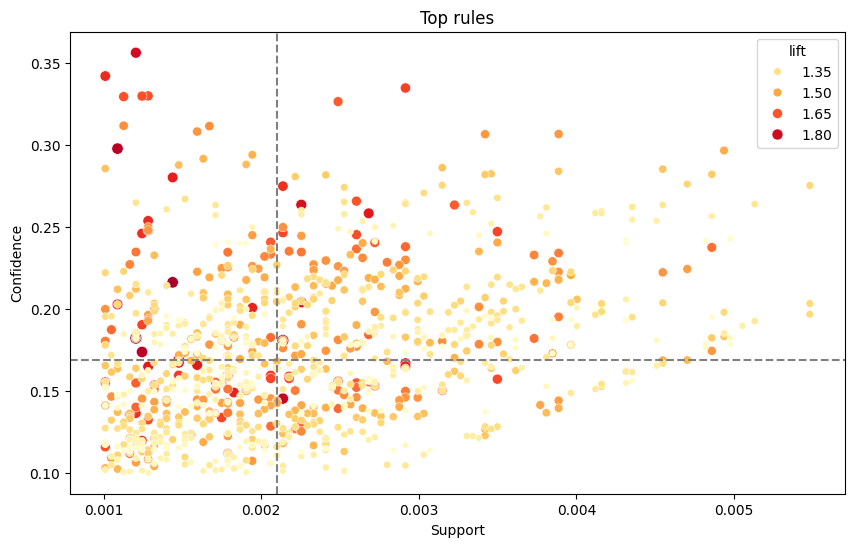

In [33]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=top_rules,
                x='support',
                y='confidence',
                size='lift',
                hue='lift',
                palette='YlOrRd')
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.axvline(x=top_rules['support'].median(), color='grey', linestyle='--')
plt.axhline(y=top_rules['confidence'].median(), color='grey', linestyle='--')
plt.title('Top rules')
plt.show()

> Rules with the strongest associations (highest lift values) are distributed across all support-confidence quadrants. This suggests that association strength is largely independent of rule popularity and conversion likelihood in the current dataset.

## **6. Label action recommendations**

In [34]:
# identified medians as the cutoff points
support_cutoff = top_rules['support'].median()
confidence_cutoff = top_rules['confidence'].median()

print(support_cutoff)
print(confidence_cutoff)

0.0020988805970149254
0.16922159105646772


In [35]:
# label action groups
def classify_rule(row):
    if row['support'] >= support_cutoff:
        if row['confidence'] >= confidence_cutoff:
            return 'Scale'
        else:
            return 'Reach'
    else:
        if row['confidence'] >= confidence_cutoff:
            return 'Precision'
        else:
            return 'Monitor'

top_rules['ActionGroup'] = top_rules.apply(
    classify_rule,
    axis=1
)

In [36]:
top_rules['ActionGroup'].value_counts()

,count
ActionGroup,
Scale,296
Monitor,288
Reach,184
Precision,176


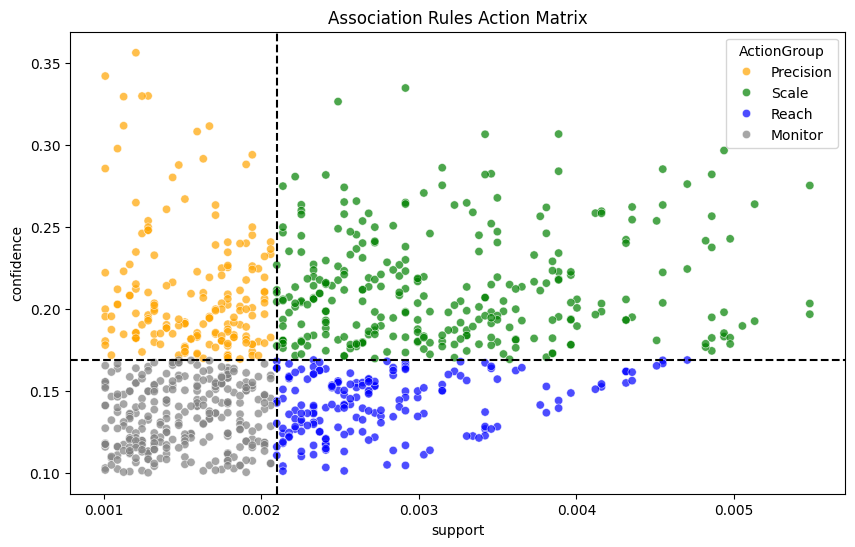

In [37]:
palette = {'Scale':'green', 'Reach':'blue', 'Precision':'orange', 'Monitor':'gray'}

plt.figure(figsize=(10,6))
sns.scatterplot(data=top_rules,
                x='support',
                y='confidence',
                hue='ActionGroup',
                palette=palette,
                alpha=0.7
                )

plt.axvline(support_cutoff,
            linestyle='--',
            color='black'
            )

plt.axhline(confidence_cutoff,
            linestyle='--',
            color='black'
            )
plt.title('Association Rules Action Matrix')
plt.show()

In [39]:
rules_dashboard = top_rules.drop(columns=['antecedents', 'consequents'])

In [41]:
rules_dashboard.to_csv(
    r'/content/drive/MyDrive/rules_dashboard.csv',
    index=False,
    encoding='utf-8-sig',
    float_format='%.4f'
)

## **7. Conclusions & Recommendations**

### **Conclusions**:
1. The most common product combinations are centered around personal care categories, including nail care, body care, hand care, bath products, and hair care.

2. The strongest associations (high lift) suggest two dominant customer needs:

* **Holistic self-care:** hair care, facial skincare, body cleansing, nail care.
* **At-home wellness spa:** personal care products purchased alongside candles, diffusers, home fragrance, and spa products.

3. Support, Confidence, and Lift capture different dimensions of customer behavior:

* Support → Popularity
* Confidence → cross-sell likelihood
* Lift → strength of association beyond probalibity of independent events

  **Little overlap exists between top rules ranked by Support, Confidence, and Lift, confirming that no single metric is sufficient for business decision-making.**

## **Recommendations for next steps:**

1. **Build a Product-page Recommendation Dashboard by PowerBI.**

* Use **Antecedents** as the starting point for analysis.
* For each product subcategory, display all associated consequents along with Support, Confidence, Lift, and Action Group.
* Enable stakeholders to explore **Recommended subcategories, Association strength, Combination popularity, and Cross-sell potential**.

2. **Prioritize Rules by Action Group**

  | Action Group | Recommended Action |
  |-----|-----|
  | Scale	| Bundles, promotions, product-page recommendations |
  | Reach	| Broad campaigns and experimentation |
  | Precision	| Personalized CRM and cross-sell recommendations |
  | Monitor	| Track and review periodically |


3. **Validate recommendation-support decisions through A/B test before mass rollout**

* Randomize eligible sessions or customers into treatment and control groups and keep assignment stable where practical.
* Measure: conversion rate, AOV uplift, revenue uplift, and margin uplift if possible.
